In [57]:
!pip install session_info
!pip install upsetplot
!pip install pyjanitor==0.23.1


In [58]:
!pip install pyreadr

In [59]:
import janitor
import matplotlib.pyplot as plt
import missingno
import numpy as np
import pandas as pd
import pyreadr
import seaborn as sns
import session_info
import upsetplot

In [60]:
!pip install --upgrade jupyter_client jupyterlab

# Load Data Frame Diabetes

In [61]:
import kagglehub
from kagglehub import KaggleDatasetAdapter

file_path = "diabetes.csv"

# Load the latest version
dibetes_df = kagglehub.load_dataset(
  KaggleDatasetAdapter.PANDAS,
  "jamaltariqcheema/pima-indians-diabetes-dataset",
  file_path,
)

dibetes_df

/tmp/ipykernel_6215/3319891819.py:7: DeprecationWarning: Use dataset_load() instead of load_dataset(). load_dataset() will be removed in a future version.
  dibetes_df = kagglehub.load_dataset(


Using Colab cache for faster access to the 'pima-indians-diabetes-dataset' dataset.


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72.0,35,169.5,33.6,0.627,50,1
1,1,85,66.0,29,102.5,26.6,0.351,31,0
2,8,183,64.0,32,169.5,23.3,0.672,32,1
3,1,89,66.0,23,94.0,28.1,0.167,21,0
4,0,137,40.0,35,168.0,43.1,2.288,33,1
...,...,...,...,...,...,...,...,...,...
763,10,101,76.0,48,180.0,32.9,0.171,63,0
764,2,122,70.0,27,102.5,36.8,0.340,27,0
765,5,121,72.0,23,112.0,26.2,0.245,30,0
766,1,126,60.0,32,169.5,30.1,0.349,47,1


# Load Data set naniar

In [62]:
base_url = "https://raw.githubusercontent.com/njtierney/naniar/main/data"
datasets_name = ("oceanbuoys","pedestrian","riskfactors")
extension_file = ".rda"

dataset_dfs = {}

!mkdir data

for dataset in datasets_name:
   dataset_file = f"{dataset}{extension_file}"
   dataset_output_file = f"data/{dataset_file}"
   dataset_url = f"{base_url}/{dataset_file}"

   !wget -q -O {dataset_output_file} {dataset_url}

   dataset_dfs[f"{dataset}_df"] = pyreadr.read_r(dataset_output_file).get(dataset)

dataset_dfs.keys()

mkdir: cannot create directory ‘data’: File exists


dict_keys(['oceanbuoys_df', 'pedestrian_df', 'riskfactors_df'])

In [63]:
locals().update(**dataset_dfs)
del dataset_dfs
#oceanbuoys_df
#pedestrian_df
#riskfactors_df

#riskfactors_df.size - riskfactors_df.isna().sum().sum()

riskfactors_df.notna().sum().sum()

np.int64(7144)

# Columns Missing Data (Varibles)

In [115]:
def number_complete(df: pd.DataFrame) -> int:
  """ Data Whitout missing values"""
  return df.size - df.isna().sum().sum()

def missing_variable_summary(df: pd.DataFrame) -> pd.DataFrame:
  return df.isnull().pipe(
      lambda df_1: (
          df_1.sum()
          .reset_index(name="n_missing")
          .rename(columns={"index": "variable"})
          .assign(
              n_cases=len(df),
              pct_missing=lambda df_2: df_2.n_missing / df_2.n_cases * 100
              )
          )
      )

def missing_variable_table(df: pd.DataFrame) -> pd.DataFrame:
  return (
      missing_variable_summary(df)
      .value_counts("n_missing")
      .reset_index()
      .rename(columns={"n_missing": "n_missing_in_variable", "count": "n_variables"})
      .assign(
          pct_variables=lambda df_1: df_1.n_variables / df_1.n_variables.sum() * 100
          ).sort_values("pct_variables", ascending=False)
        )

#missing_variable_summary(riskfactors_df).sort_values("n_missing")
missing_variable_summary(riskfactors_df)


,variable,n_missing,n_cases,pct_missing
0,state,0,245,0.000000
1,sex,0,245,0.000000
2,age,0,245,0.000000
3,weight_lbs,10,245,4.081633
4,height_inch,2,245,0.816327
5,bmi,11,245,4.489796
6,marital,1,245,0.408163
7,pregnant,215,245,87.755102
8,children,0,245,0.000000
9,education,1,245,0.408163


# Rows missing Data (Cases)

In [65]:
def missing_case_summary(df: pd.DataFrame) -> pd.DataFrame:
        return df.assign(
            case=lambda df: df.index,
            n_missing=lambda df: df.apply(
                axis="columns", func=lambda row: row.isna().sum()
            ),
            n_variables = df.shape[1],
            pct_missing= lambda df_1: df_1.n_missing / df_1.shape[1] * 100
        )[['case', 'n_missing',	'n_variables', 'pct_missing']]

def missing_case_table(df: pd.DataFrame) -> pd.DataFrame:
  return (
      missing_case_summary(df)
      .value_counts("n_missing")
      .reset_index()
      .rename(columns={"n_missing": "n_missing_in_cases", "count": "n_cases"})
      .assign(
          pct_cases=lambda df_1: df_1.n_cases / df_1.n_cases.sum() * 100
          ).sort_values("pct_cases", ascending=False)
        )

missing_case_table(riskfactors_df)

,n_missing_in_cases,n_cases,pct_cases
0,4,49,20.000000
1,5,45,18.367347
2,7,39,15.918367
3,6,36,14.693878
4,2,31,12.653061
5,3,30,12.244898
6,1,4,1.632653
7,8,3,1.224490
8,12,3,1.224490
9,15,2,0.816327


#Missing per variable

In [66]:
import itertools

def missing_variable_run(df: pd.pandas, variable) -> pd.DataFrame:
  rle_list = df[variable].pipe(
      lambda s: [[len(list(g)), k] for k, g in itertools.groupby(s.isnull())]
      )
  return pd.DataFrame(data=rle_list, columns=["missing_case_table", "is_na"]).replace(
      {False: "complete", True: "missing"}
      )

missing_variable_run(riskfactors_df,"health_poor")

,missing_case_table,is_na
0,2,complete
1,5,missing
2,3,complete
3,1,missing
4,2,complete
...,...,...
121,3,missing
122,3,complete
123,2,missing
124,1,complete


#Plot Missing Variables

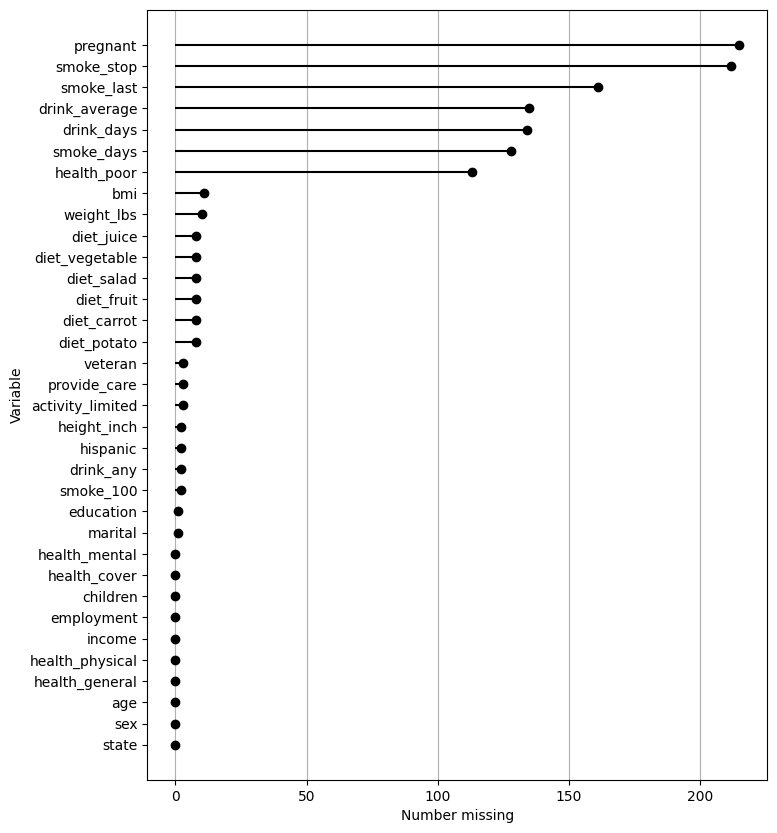

In [67]:
from matplotlib import figure

def missing_variable_plot(df : pd.DataFrame) -> None:

  df_plot = missing_variable_summary(df).sort_values("n_missing")

  plot_range = range(1, len(df_plot.index) + 1)

  plt.figure(figsize=(8, 10))

  plt.hlines(y=plot_range, xmin=0, xmax=df_plot.n_missing, color="black")

  plt.plot(df_plot.n_missing, plot_range, "o", color="black")

  plt.yticks(plot_range, df_plot.variable)

  plt.grid(axis="x")

  plt.xlabel("Number missing")
  plt.ylabel("Variable")

missing_variable_plot(riskfactors_df)

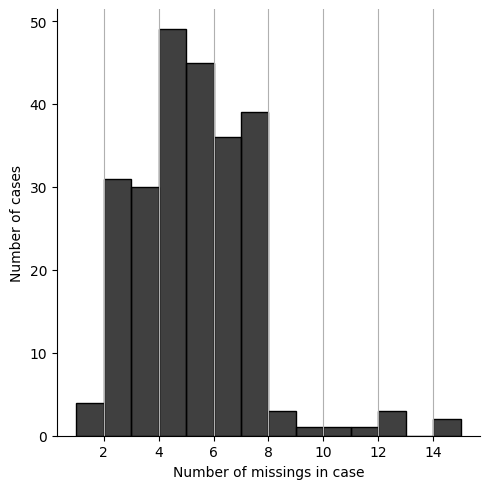

In [68]:
def missing_case_plot(df:pd.DataFrame):

  df_plot = missing_case_summary(df)

  sns.displot(data=df_plot, x="n_missing", binwidth=1, color="black")

  plt.grid(axis="x")
  plt.xlabel("Number of missings in case")
  plt.ylabel("Number of cases")

missing_case_plot(riskfactors_df)

/usr/local/lib/python3.12/dist-packages/upsetplot/plotting.py:795: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  styles["linewidth"].fillna(1, inplace=True)
/usr/local/lib/python3.12/dist-packages/upsetplot/plotting.py:796: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example,

{'matrix': <Axes: >,
 'shading': <Axes: >,
 'totals': <Axes: >,
 'intersections': <Axes: ylabel='Intersection size'>}

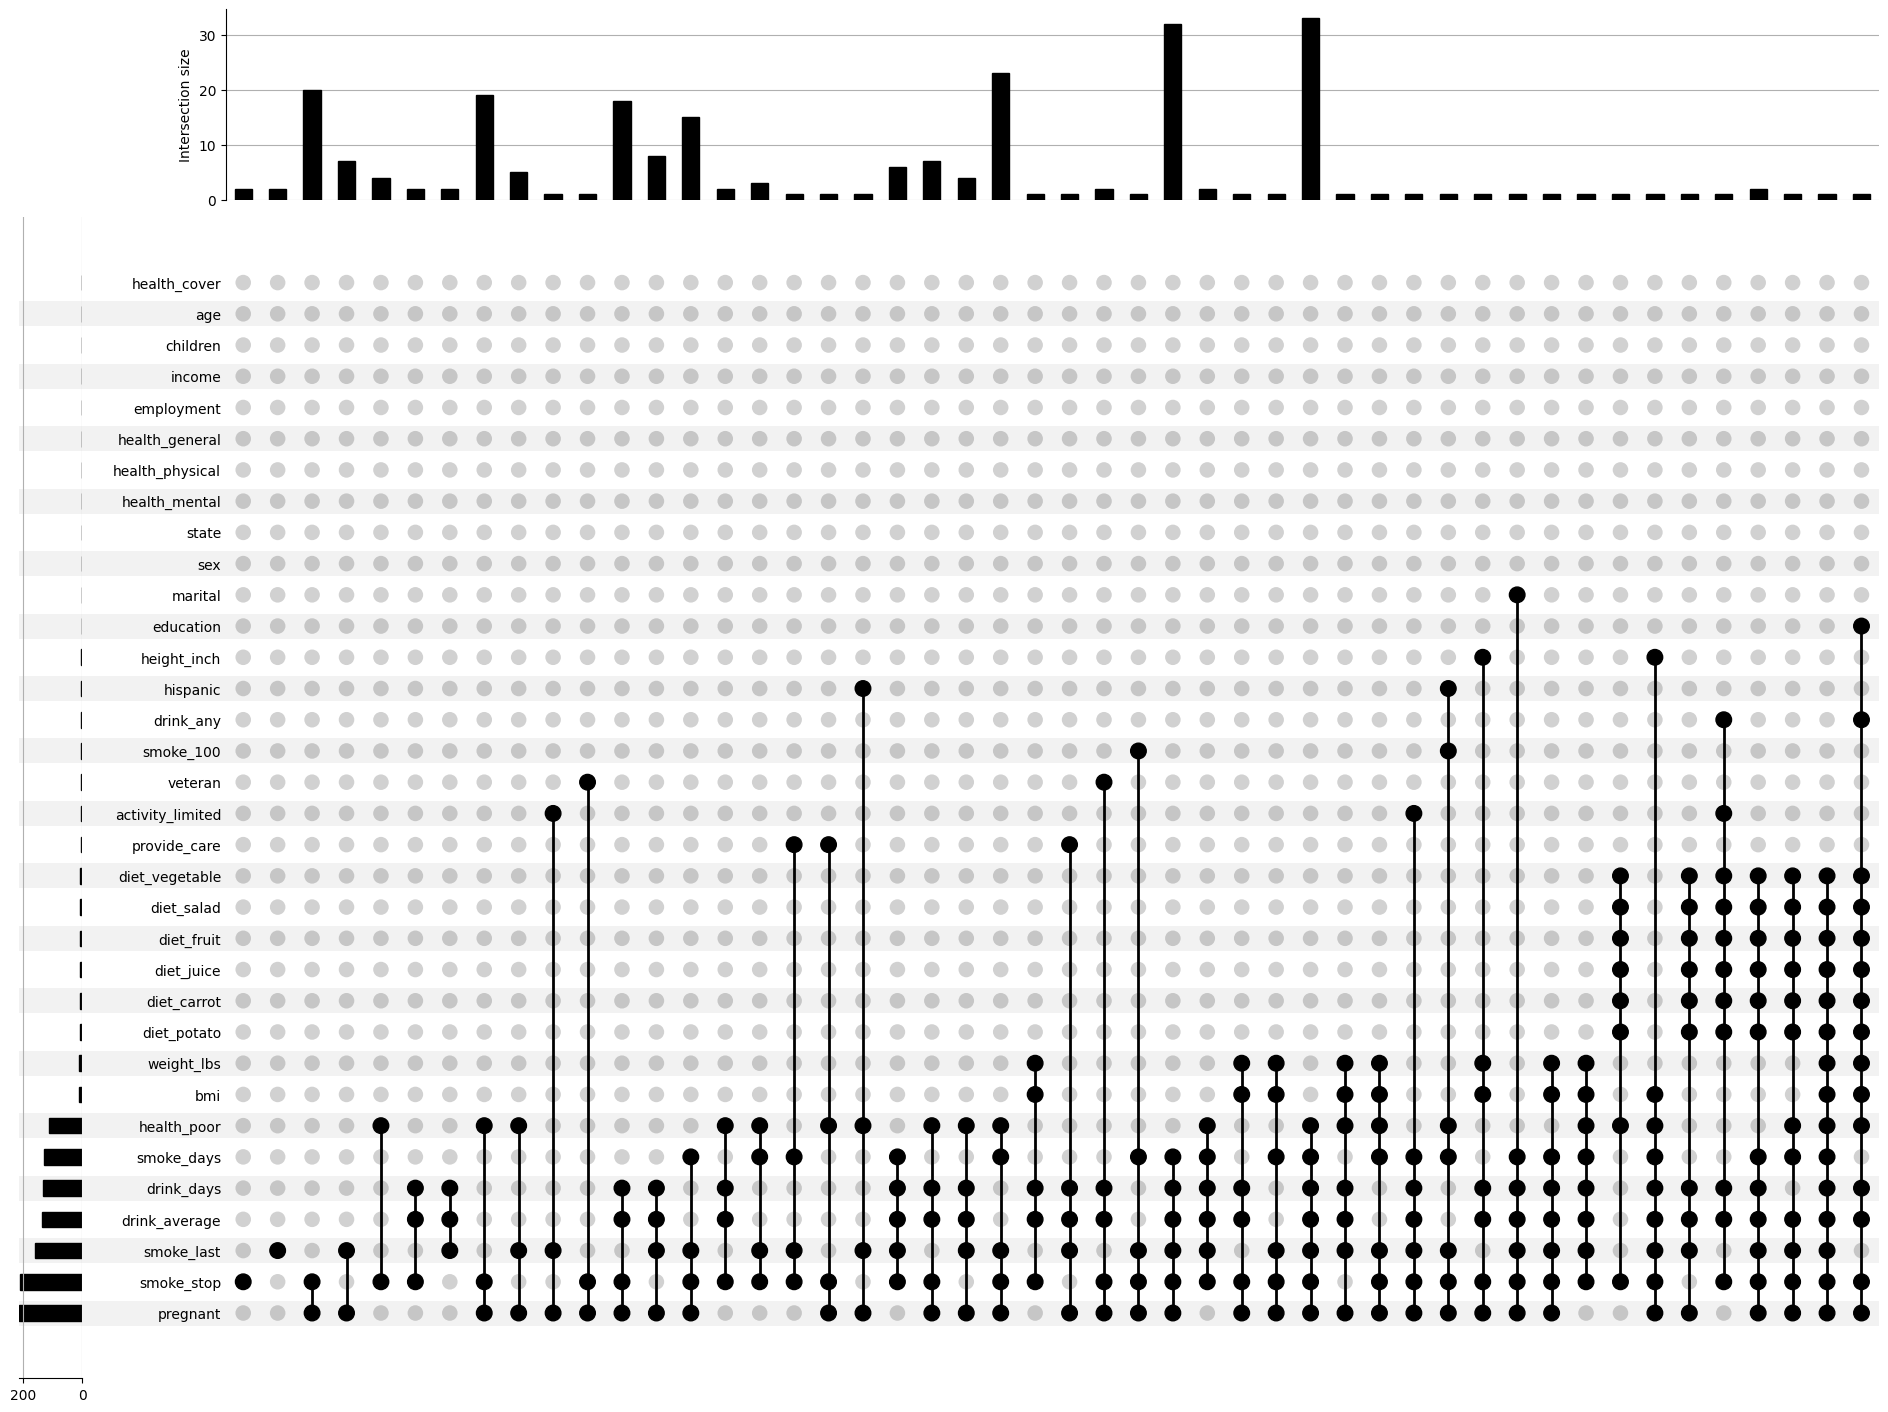

In [69]:
### Esto es un diagrama de Ven
def missing_upsetplot(df: pd.DataFrame, variables: list[str] = None, **kwargs):
  if variables is None:
    variables = df.columns.tolist()

  return (
      df.isna()
      .value_counts(variables)
      .pipe(lambda df_plot: upsetplot.plot(df_plot, **kwargs))
      )

missing_upsetplot(variables=None,df=riskfactors_df)

#Ussing Dependenci missingno

<Axes: >

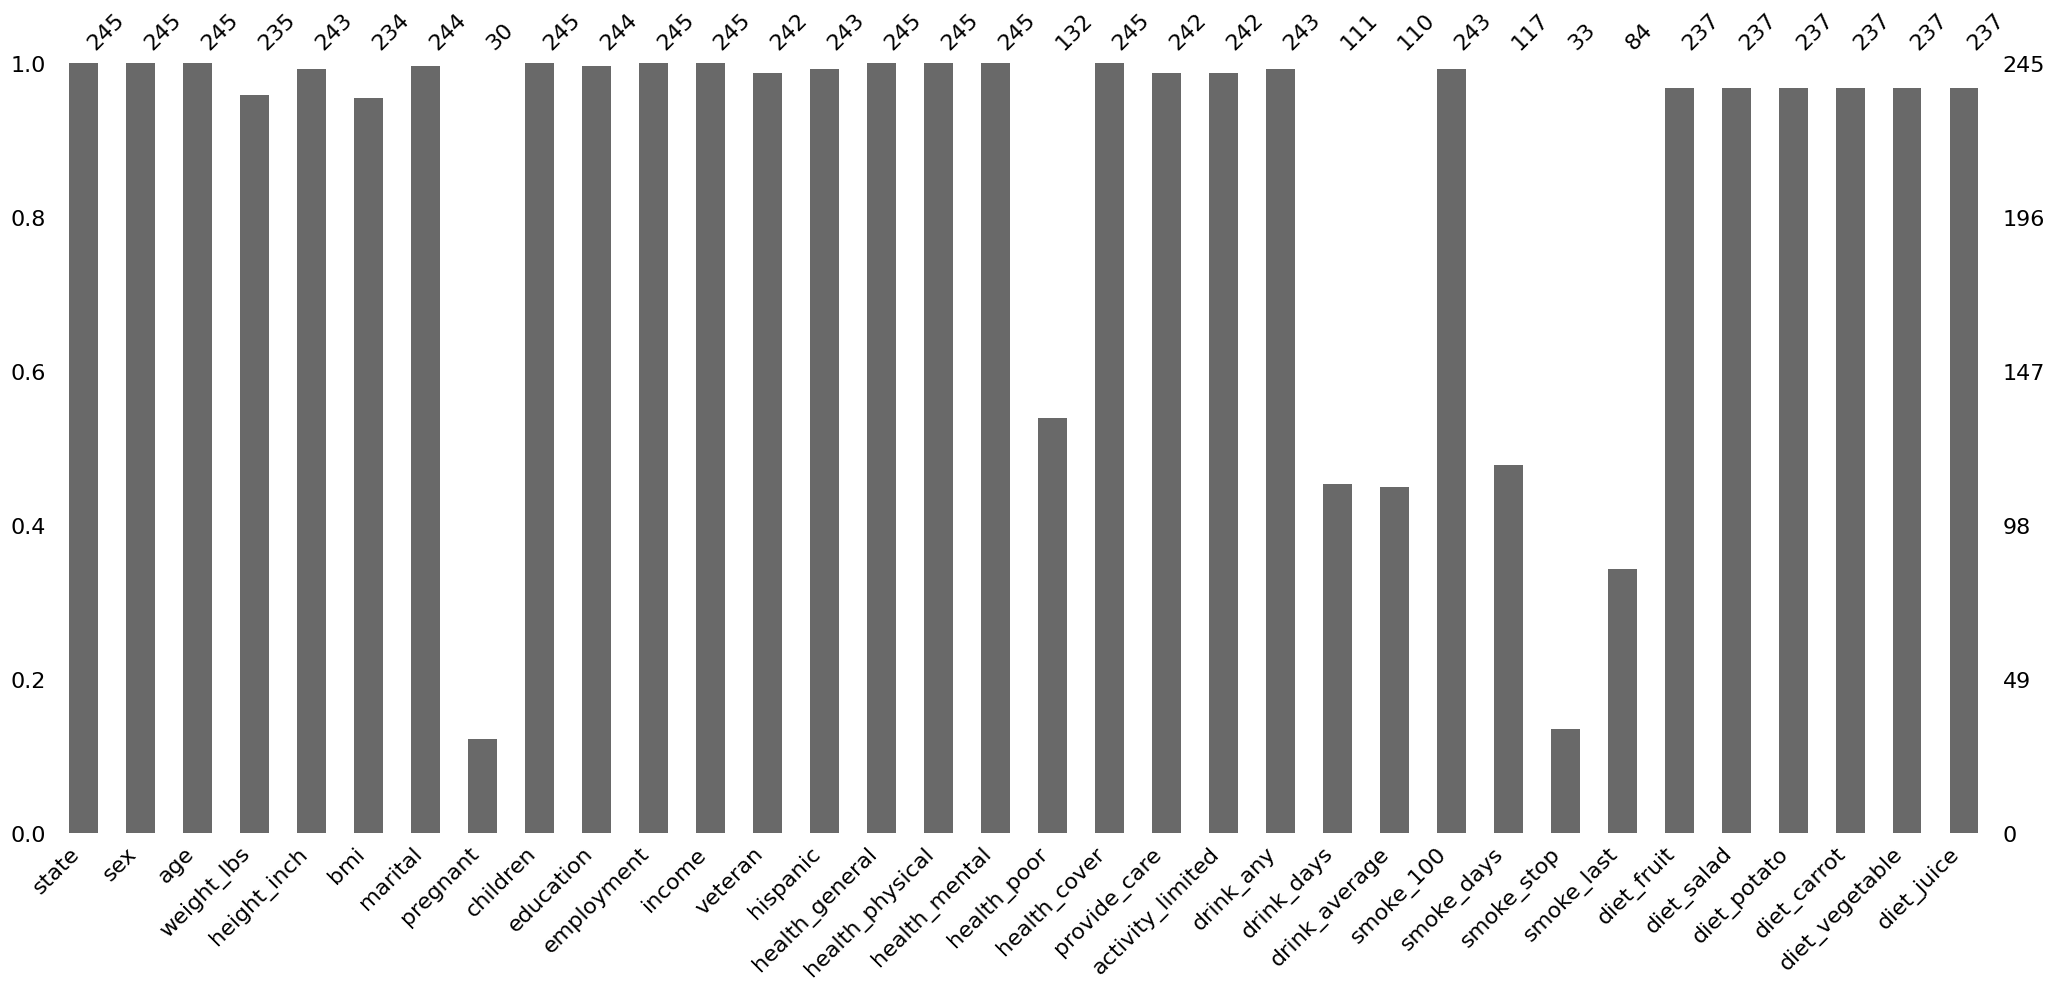

In [70]:
missingno.bar(df=riskfactors_df)

<Axes: >

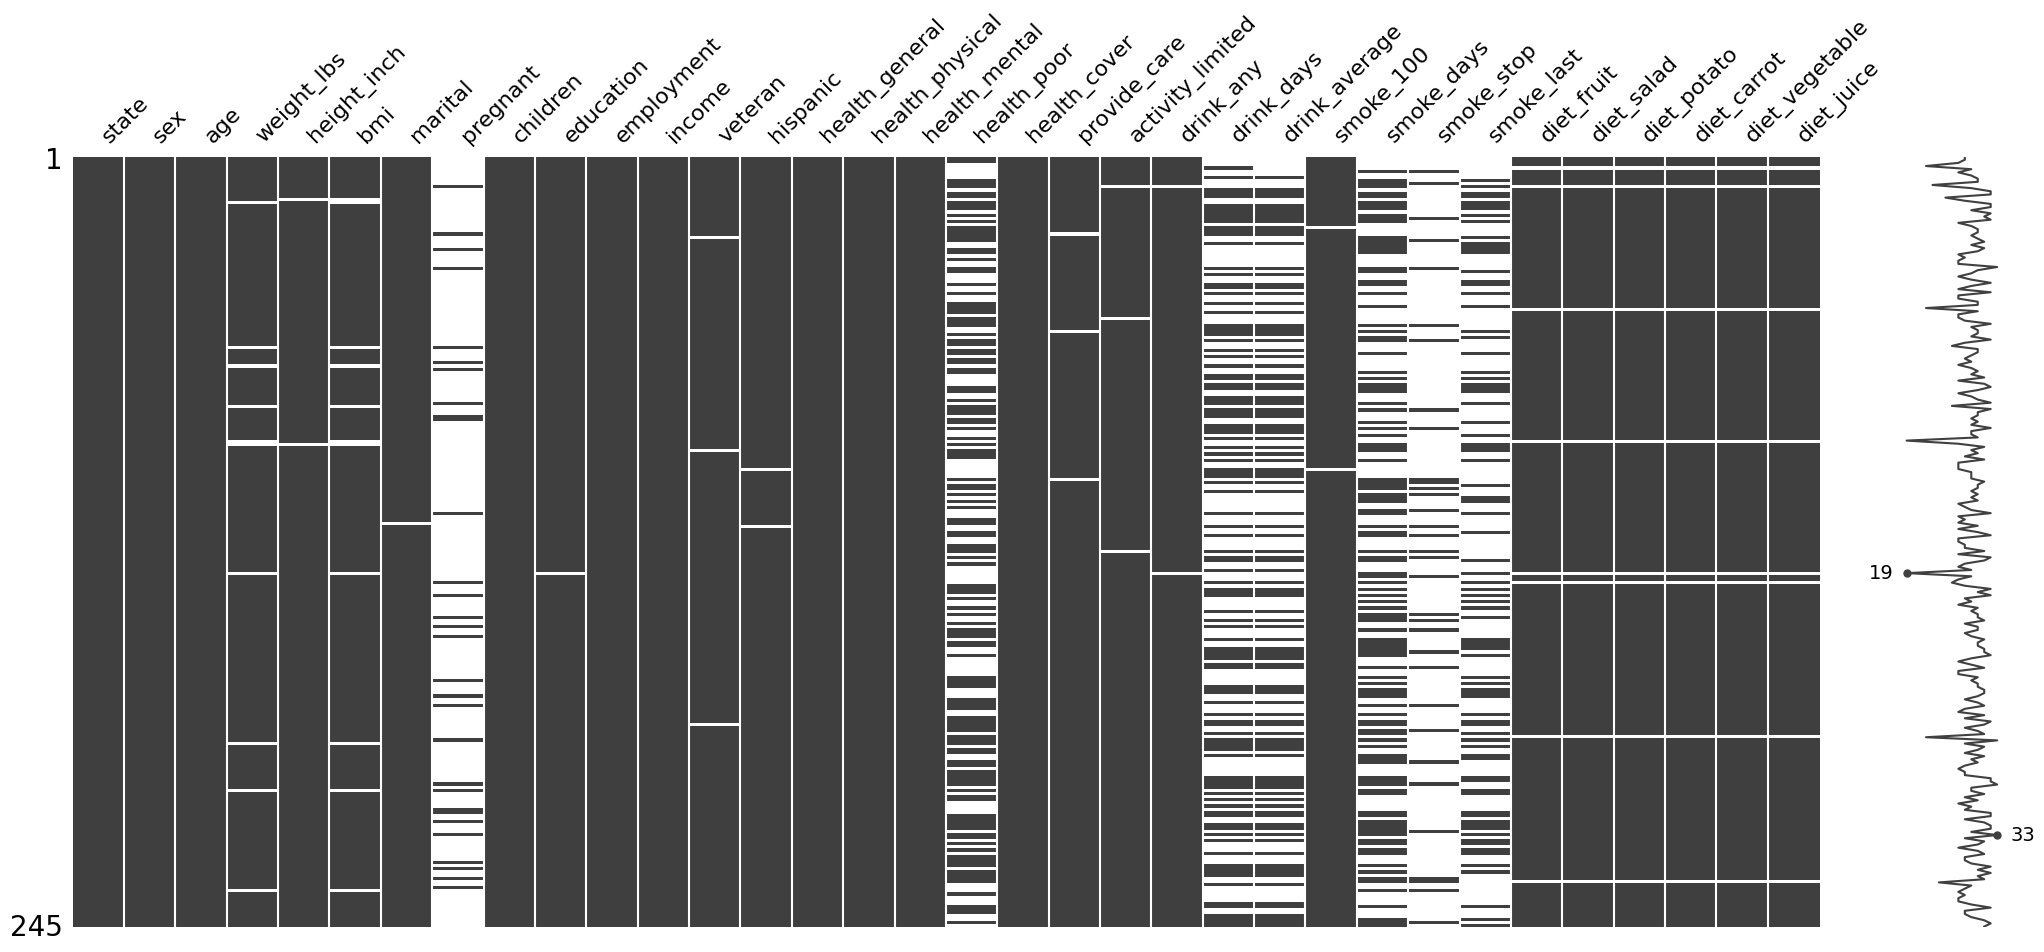

In [71]:
missingno.matrix(df=riskfactors_df)

# Missing Variables Codification

In [72]:
implicit_to_explicit_df = pd.DataFrame.from_dict(
    data={
        "name": ["lynn", "lynn", "lynn", "zelda"],
        "time": ["morning", "afternoon", "night", "morning"],
        "value": [350, 310, np.nan, 320]
    }
)

implicit_to_explicit_df

,name,time,value
0,lynn,morning,350.0
1,lynn,afternoon,310.0
2,lynn,night,NaN
3,zelda,morning,320.0


In [73]:
##pivot
implicit_to_explicit_df.pivot(index="name", columns="time", values="value")

time,afternoon,morning,night
name,,,
lynn,310.0,350.0,NaN
zelda,NaN,320.0,NaN


In [74]:
implicit_to_explicit_df.value_counts("name").reset_index(name="n")

,name,n
0,lynn,3
1,zelda,1


# **USING JANITOR**

In [75]:
implicit_to_explicit_df

,name,time,value
0,lynn,morning,350.0
1,lynn,afternoon,310.0
2,lynn,night,NaN
3,zelda,morning,320.0


In [76]:
implicit_to_explicit_df.complete("name","time")

,name,time,value
0,lynn,afternoon,310.0
1,lynn,morning,350.0
2,lynn,night,NaN
3,zelda,afternoon,NaN
4,zelda,morning,320.0
5,zelda,night,NaN


In [77]:
implicit_to_explicit_df.complete({"name": ["lynn", "zelda"]},
                                 {"time": ["morning","afternoon"]},
                                 sort=True)

,name,time,value
0,lynn,afternoon,310.0
1,lynn,morning,350.0
2,lynn,night,NaN
3,zelda,afternoon,NaN
4,zelda,morning,320.0


# **Missinf data types**



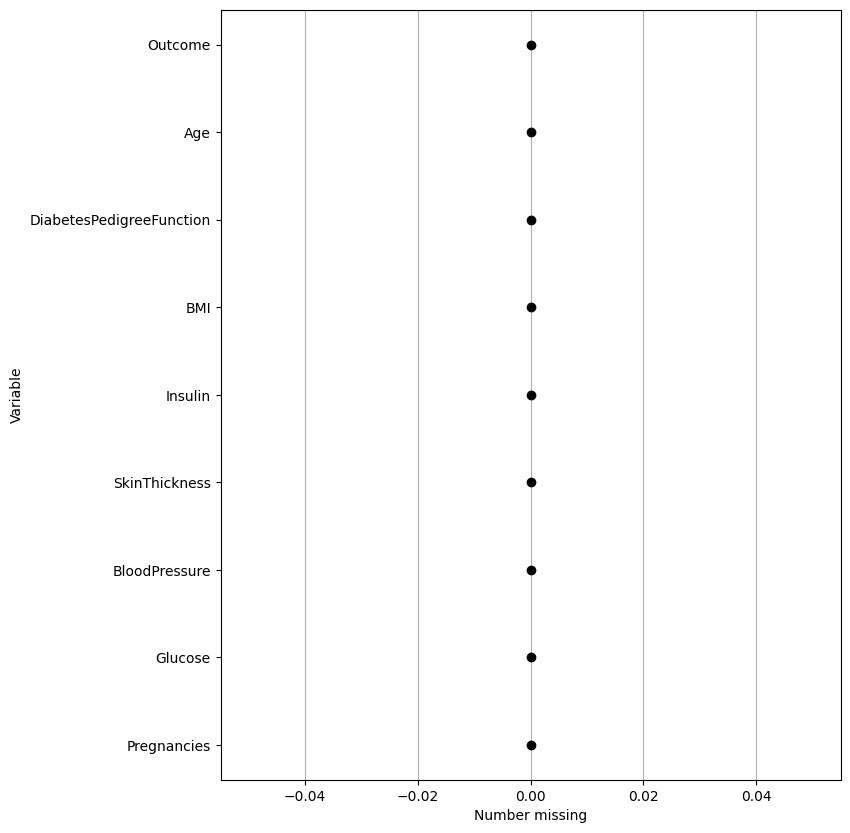

In [78]:
missing_variable_plot(dibetes_df)

In [79]:
# Filtra las filas que tienen un 0 en las columnas de la 1 a la 5
dibetes_df[(dibetes_df.iloc[:, 0:6] == 0).any(axis=1)]


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
4,0,137,40.0,35,168.0,43.1,2.288,33,1
16,0,118,84.0,47,230.0,45.8,0.551,31,1
45,0,180,66.0,39,169.5,42.0,1.893,25,1
57,0,100,88.0,60,110.0,46.8,0.962,31,0
58,0,146,82.0,27,102.5,40.5,1.781,44,0
...,...,...,...,...,...,...,...,...,...
713,0,134,58.0,20,291.0,26.4,0.352,21,0
727,0,141,84.0,26,102.5,32.4,0.433,22,0
736,0,126,86.0,27,120.0,27.4,0.515,21,0
753,0,181,88.0,44,510.0,43.3,0.222,26,1


<Axes: >

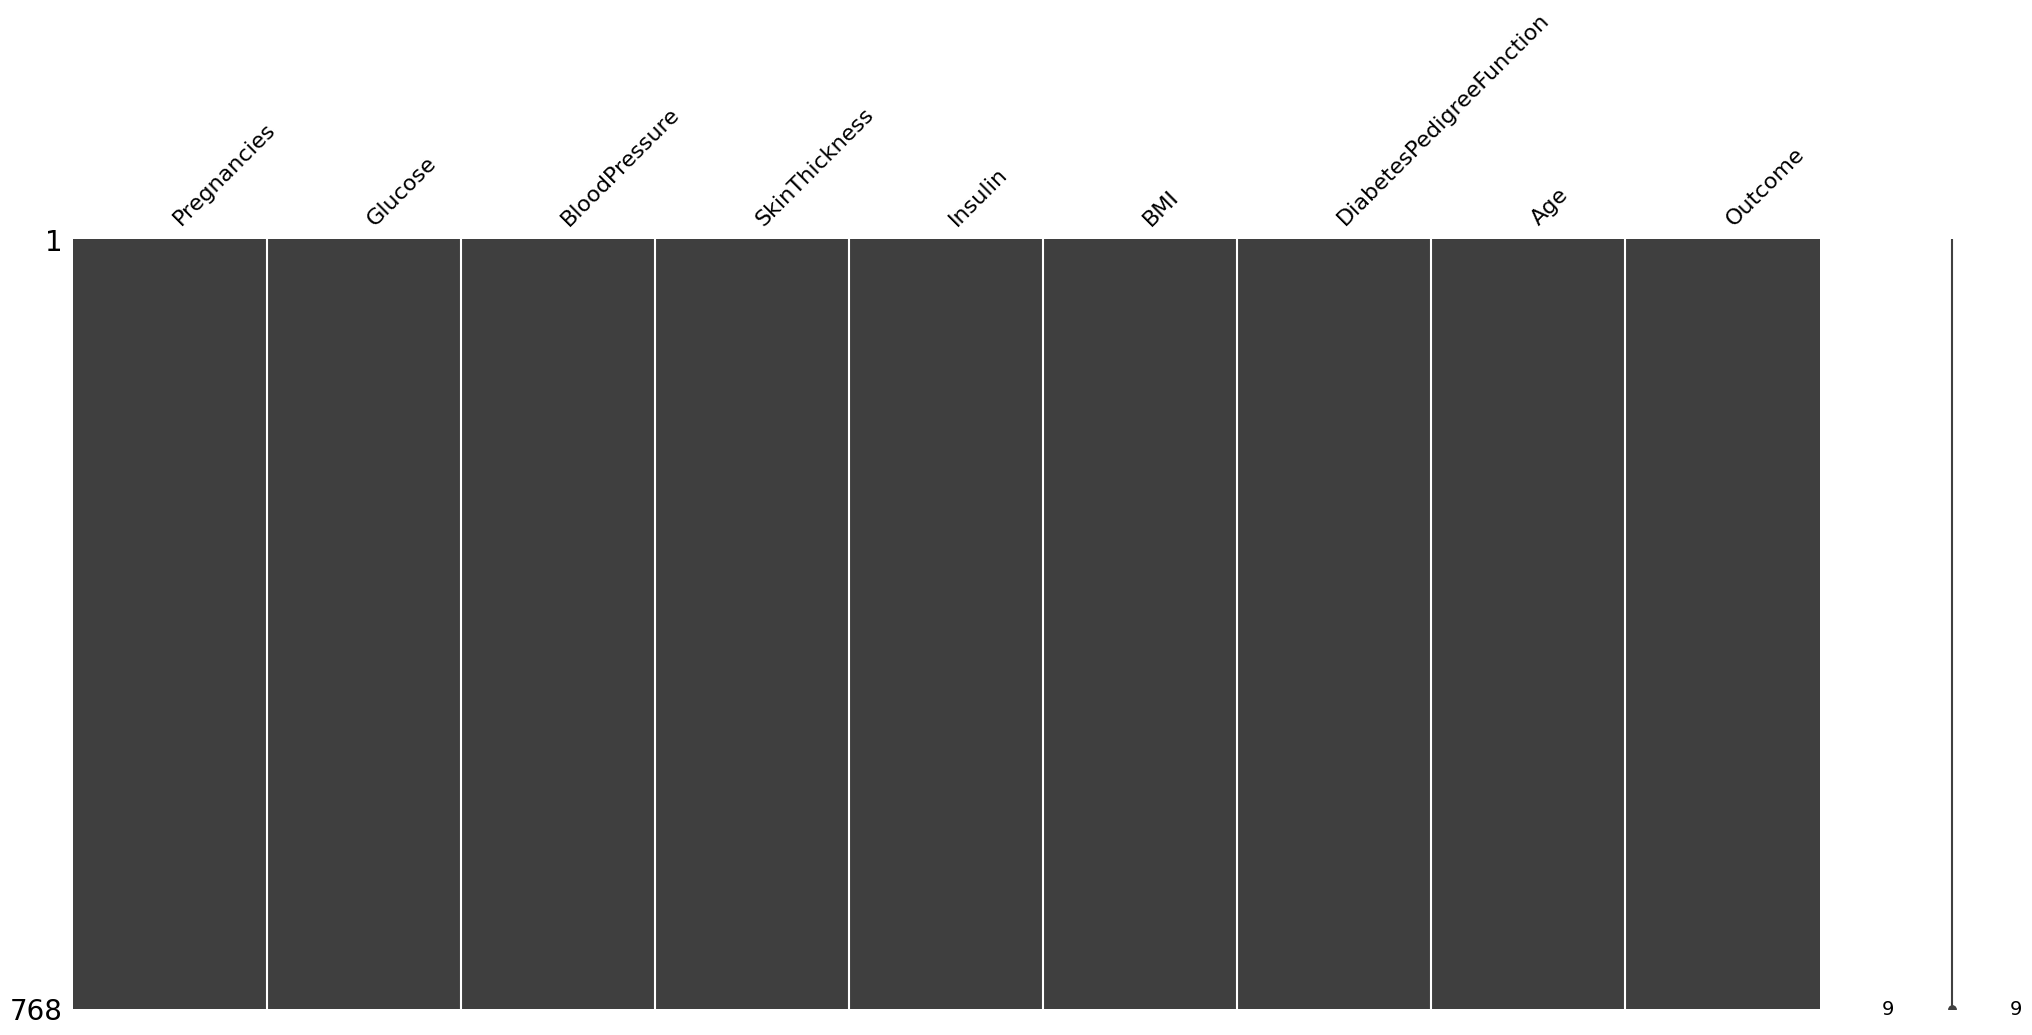

In [80]:
missingno.matrix(df=dibetes_df)

In [81]:
from pandas.core.reshape import concat
import pandas as pd

def create_shadow_matrix(
    df: pd.DataFrame,
    true_missing: str = "Missing",
    false_string: str = "Not Missing",
    only_missing: bool = False
) -> pd.DataFrame:

    na_mask = df.isna()
    if only_missing:
        cols_with_na = df.columns[na_mask.any()]
        na_mask = na_mask[cols_with_na]

    # 4. Combine original data with shadow matrix
    return (pd.concat([df, na_mask.replace({True: true_missing, False: false_string})
      .add_suffix("_NA")], axis="columns")
    )



create_shadow_matrix(riskfactors_df,only_missing="True").groupby(["weight_lbs_NA"])["age"].describe()

,count,mean,std,min,25%,50%,75%,max
weight_lbs_NA,,,,,,,,
Missing,10.0,60.100000,13.706851,37.0,52.25,62.5,65.0,82.0
Not Missing,235.0,58.021277,17.662904,7.0,47.50,59.0,70.0,97.0


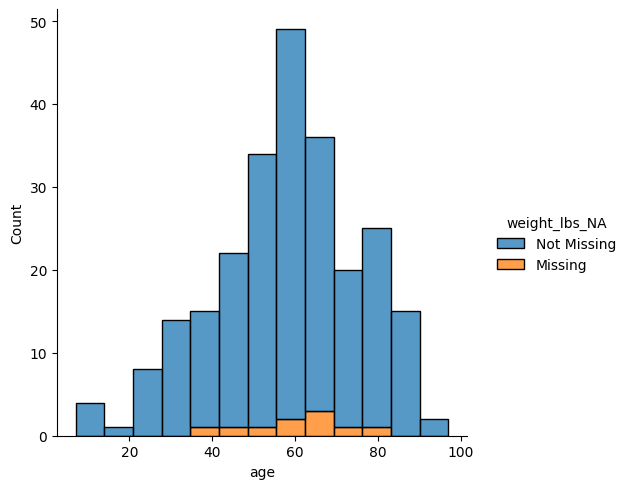

In [82]:
#create_shadow_matrix(riskfactors_df,only_missing="True").pipe(
#    lambda df: (
#        sns.boxenplot(data=df, x="weight_lbs_NA", y="age")
#    )
#)

create_shadow_matrix(riskfactors_df,only_missing="True").pipe(
    lambda df: (
        sns.displot(data=df, x="age", hue="weight_lbs_NA", multiple="stack")
    )
)

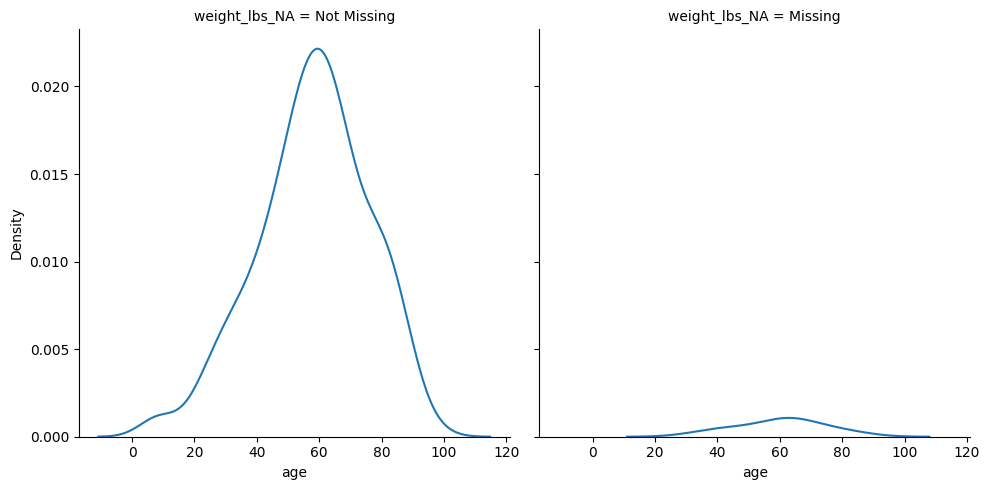

In [83]:
create_shadow_matrix(riskfactors_df,only_missing="True").pipe(
    lambda df: (
        sns.displot(data=df, x="age", col="weight_lbs_NA", kind="kde")
    )
)

# **Missing Data PLot in two variables**

In [84]:
def colum_fill_with_dummies(column: pd.Series,proportion_below: float=0.05,jitter:float=0.075,seed:int=42) -> pd.Series:
  columm = column.copy(deep=True)

  #Extract values metadata

  missing_mask = columm.isna()
  number_missing_values = missing_mask.sum()
  column_range = column.max() - column.min()

  #shif Data
  column_shif = column.min() - column.min() * proportion_below

  #Create the Jitter (noise) around the points
  np.random.seed(seed)
  column_jitter = (np.random.rand(number_missing_values)-2) * column_range * jitter

  column[missing_mask] = column_shif + column_jitter

  return column

<Axes: xlabel='weight_lbs', ylabel='height_inch'>

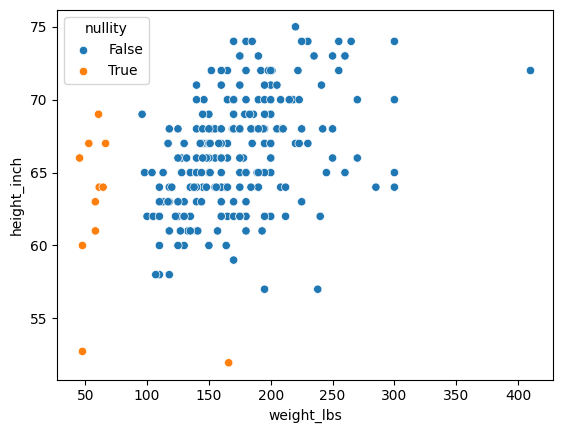

In [85]:
riskfactors_df.select_dtypes(exclude="category").pipe(
      lambda df: df[df.columns[df.isna().any()]]
    ).pipe(
      lambda df_1: create_shadow_matrix(df=df_1,false_string=False, true_missing=True)
    ).apply(
      lambda column: column if "_NA" in column.name else colum_fill_with_dummies(column)
    ).assign(
        nullity = lambda df: df.weight_lbs_NA | df.height_inch_NA
    ).pipe(
      lambda df : (
          sns.scatterplot(data=df, x="weight_lbs", y="height_inch", hue="nullity")
      )
    )




# **Nullity Correlation**

<Axes: >

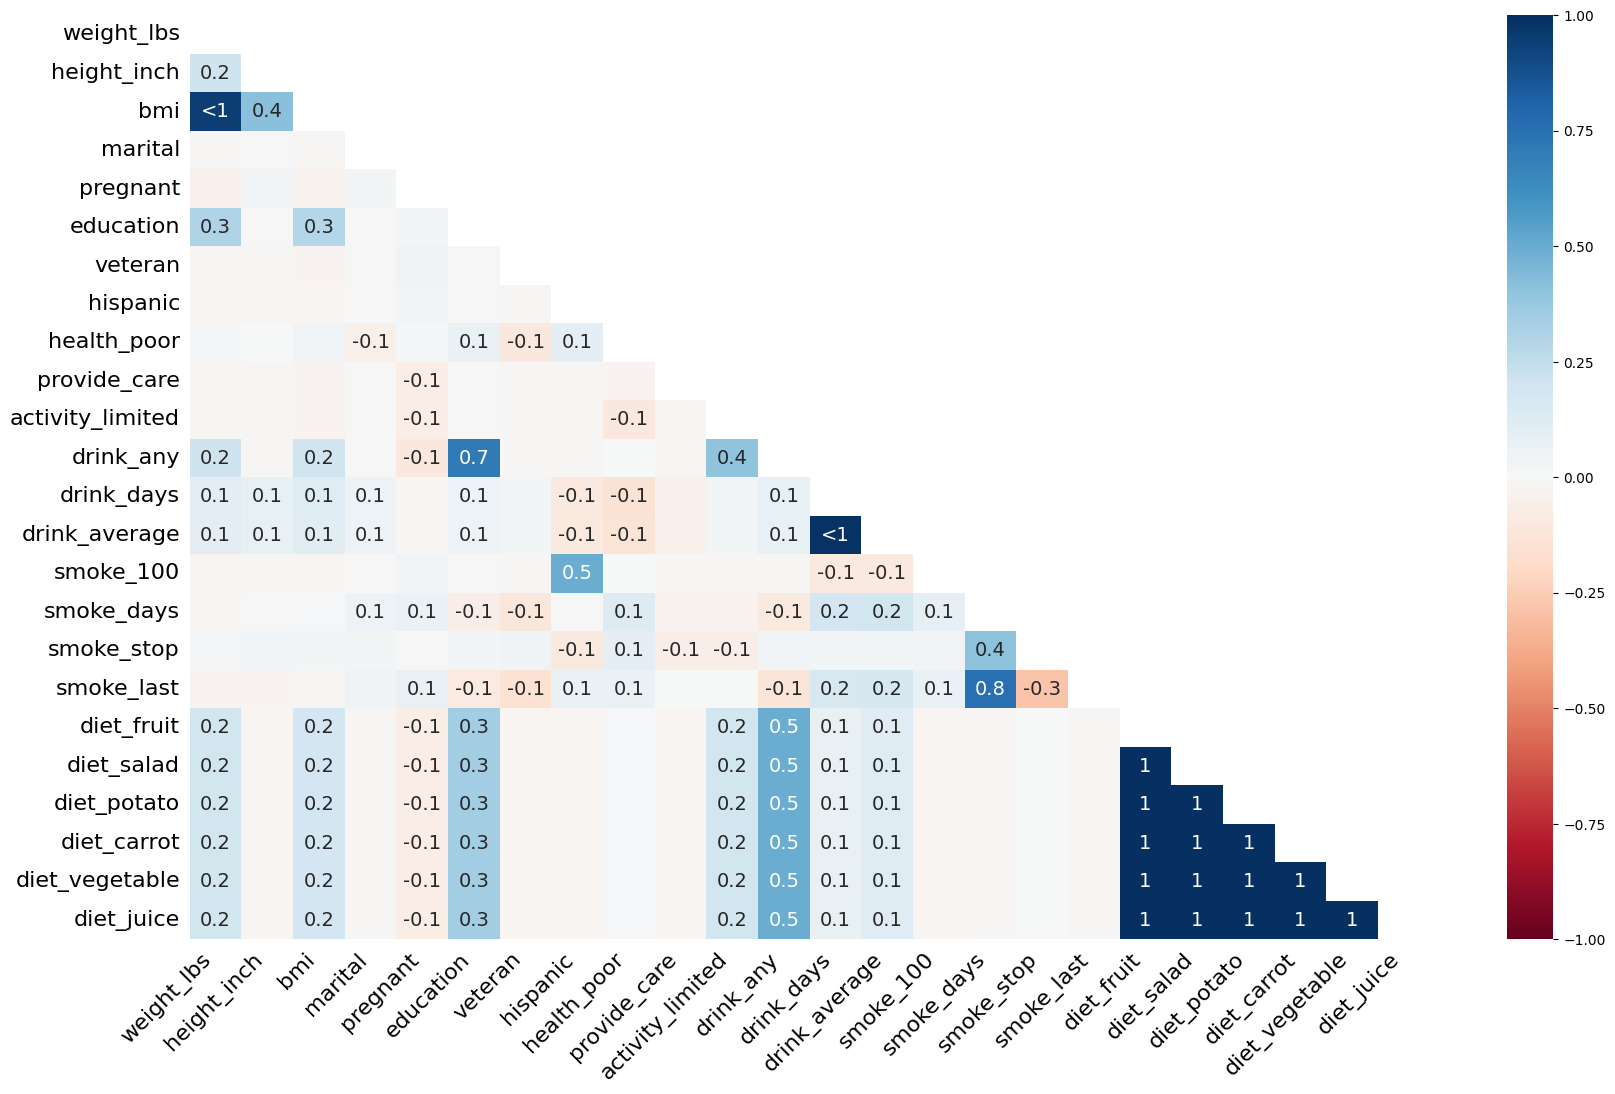

In [86]:
missingno.heatmap(
    df=riskfactors_df
)

<Axes: >

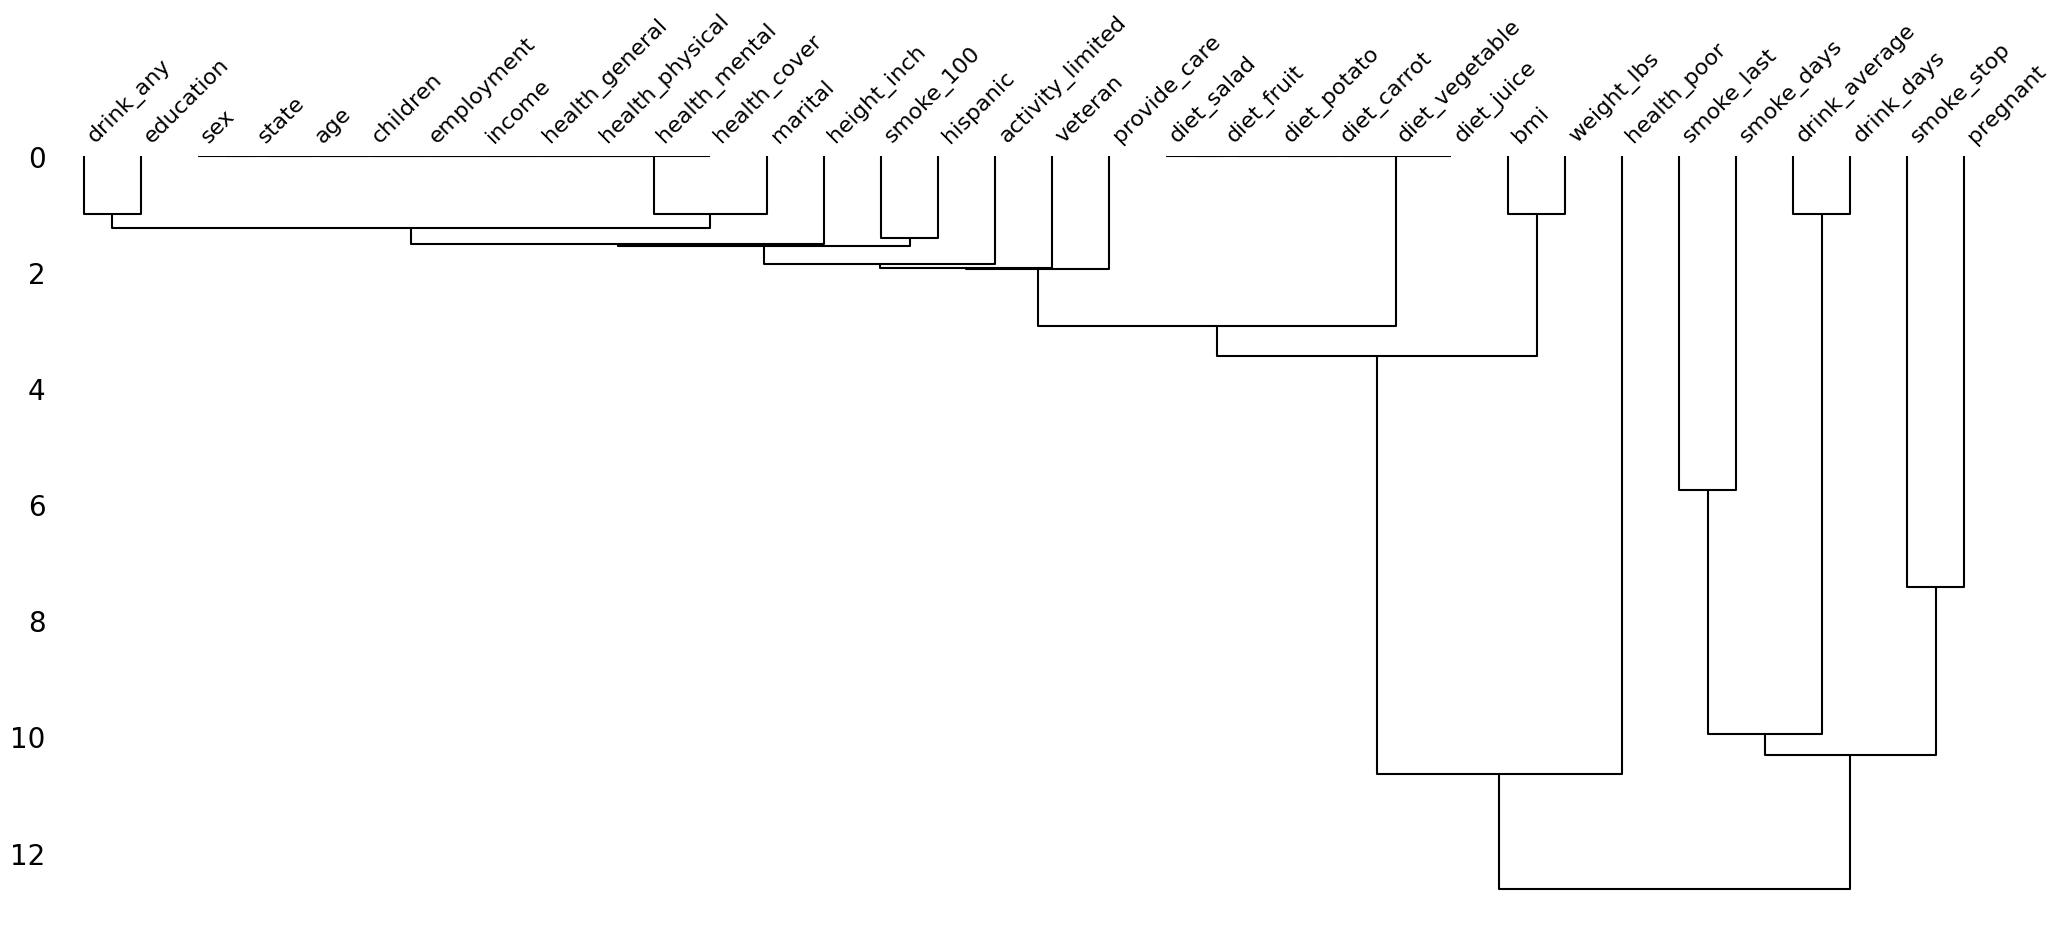

In [87]:
missingno.dendrogram(
    df=riskfactors_df
)

# **Delete Missing Data**

In [121]:
riskfactors_df.dropna(
    subset=["pregnant","smoke_stop"],
    how="all"
).shape


(59, 34)